In [1]:
# =============================================================================
# COM7003 Artificial Intelligence — Assessment 1
# Topic: Predicting CO₂ Emissions from Commercial Aviation: A Machine Learning Regression Approach

# Dataset: AeroSCOPE — Open-source global aviation traffic dataset
# Source : Salgas et al. (2023), Zenodo
#          https://doi.org/10.5281/zenodo.10125899
# Journal: https://doi.org/10.59490/joas.2023.7201
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =============================================================================
# Section 1 — Data Gathering
# =============================================================================

# dataset source — printed here so it appears clearly in the notebook output
print('Dataset source: Salgas et al. (2023). AeroSCOPE: Open-source global')
print('aviation traffic dataset. Zenodo. https://doi.org/10.5281/zenodo.10125899')
print()

# load the raw data and do a quick sanity check on shape and types
df = pd.read_csv('AeroSCOPE_global_aviation_traffic_dataset_16_11.csv')

print('rows, cols:', df.shape)
print(df.head())
print(df.dtypes)
print(df.describe())


Dataset source: Salgas et al. (2023). AeroSCOPE: Open-source global
aviation traffic dataset. Zenodo. https://doi.org/10.5281/zenodo.10125899

rows, cols: (293838, 26)
   Unnamed: 0 airline_iata acft_icao acft_class seymour_proxy source  seats  \
0           0           5V      PC12         TP          PC12    BTS    4.5   
1           1           5V      C208         TP          C208    BTS    4.5   
2           2           5V      PC12         TP          PC12    BTS    4.5   
3           3           5V      C208         TP          C208    BTS    4.5   
4           4           5V      PC12         TP          PC12    BTS    9.0   

   n_flights iata_departure iata_arrival  ...  arrival_country  \
0        0.5            05A          AET  ...               US   
1        0.5            05A          AKP  ...               US   
2        0.5            05A          AKP  ...               US   
3        0.5            05A          ARC  ...               US   
4        1.0            05A

                      Missing        Pct
Unnamed: 0                  0   0.000000
airline_iata            33408  11.369530
acft_icao               39432  13.419639
acft_class              39432  13.419639
seymour_proxy           39432  13.419639
source                      0   0.000000
seats                       0   0.000000
n_flights               39432  13.419639
iata_departure              0   0.000000
iata_arrival                0   0.000000
departure_lon              17   0.005786
departure_lat              17   0.005786
departure_country          51   0.017357
departure_continent    127728  43.468850
arrival_lon                17   0.005786
arrival_lat                17   0.005786
arrival_country            51   0.017357
arrival_continent      127728  43.468850
seats_no_est_scaling        0   0.000000
distance_km                 0   0.000000
ask                         0   0.000000
rpk                         0   0.000000
fuel_burn_seymour       42394  14.427678
fuel_burn       

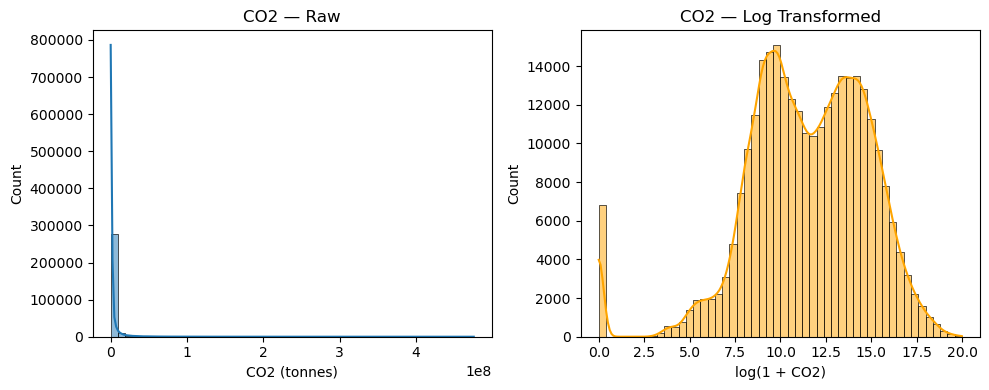

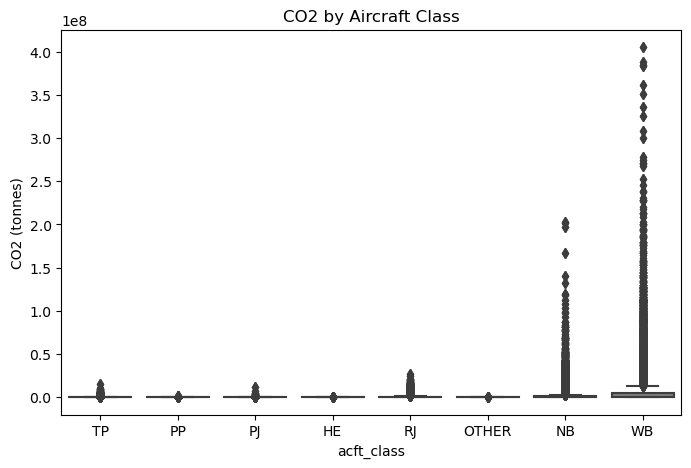

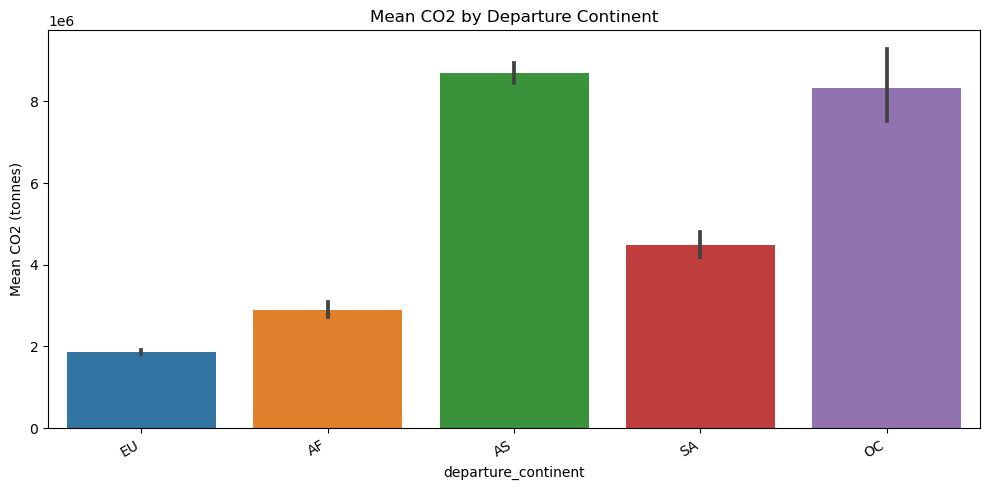

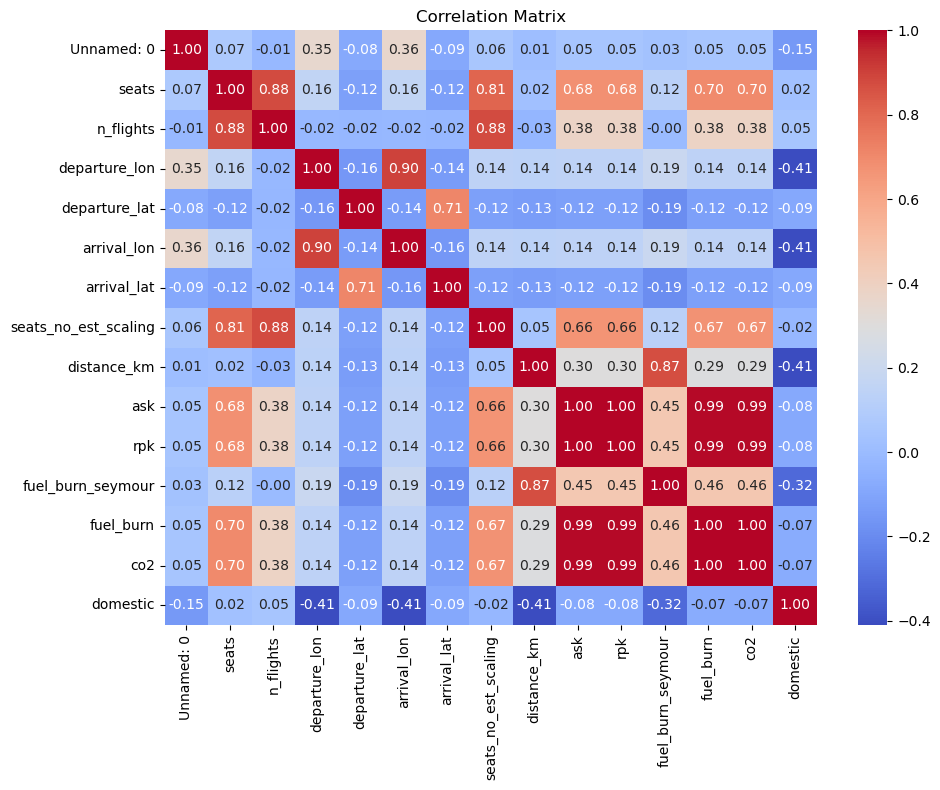

Top 10 highest-emission routes:
iata_departure  iata_arrival
CUN             MEX             475888045.4
MEX             CUN             475888045.4
AMD             DEL             461307232.8
DEL             AMD             461307232.8
DXB             SYD             449390082.3
SYD             DXB             449390082.3
MEL             SIN             438852474.3
SIN             MEL             438852474.3
DXB             MEL             426427837.9
MEL             DXB             426427837.9
Name: co2, dtype: float64


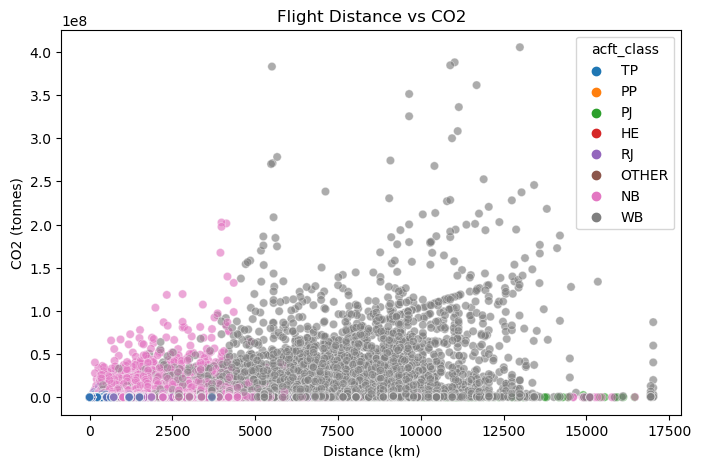

In [ ]:
# =============================================================================
# Section 2 — Exploratory Data Analysis
# =============================================================================

# --- 2.1 missing values ---
# want to see which columns are patchy before deciding what to drop vs impute
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df)) * 100
print(pd.DataFrame({'Missing': missing_count, 'Pct': missing_pct}))

# --- 2.2 CO2 distribution ---
# expecting a right skew since a small number of long-haul routes will dominate
# plotting raw and log-transformed side by side to confirm
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(df['co2'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('CO2 — Raw')
axes[0].set_xlabel('CO2 (tonnes)')

sns.histplot(np.log1p(df['co2']), bins=50, kde=True, color='orange', ax=axes[1])
axes[1].set_title('CO2 — Log Transformed')
axes[1].set_xlabel('log(1 + CO2)')

plt.tight_layout()
plt.savefig('co2_distribution.png')
plt.show()

# --- 2.3 emissions by aircraft class ---
# if aircraft class carries real information, it should be seen clear separation here
plt.figure(figsize=(8, 5))
sns.boxplot(x='acft_class', y='co2', data=df)
plt.title('CO2 by Aircraft Class')
plt.ylabel('CO2 (tonnes)')
plt.savefig('co2_by_acft_class.png')
plt.show()

# --- 2.4 average CO2 by departure continent ---
# using continent rather than country — country has hundreds of unique values
# and the barplot becomes unreadable; continent gives 5-6 meaningful groups
plt.figure(figsize=(10, 5))
sns.barplot(x='departure_continent', y='co2', data=df, estimator=np.mean)
plt.xticks(rotation=30, ha='right')
plt.title('Mean CO2 by Departure Continent')
plt.ylabel('Mean CO2 (tonnes)')
plt.tight_layout()
plt.savefig('co2_by_continent.png')
plt.show()

# --- 2.5 correlation heatmap ---
# just looking at numerics for now; this helps me spot which features
# might be redundant or which ones correlate strongly with the target
num_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

# --- 2.6 top 10 routes by mean CO2 ---
top_routes = df.groupby(['iata_departure', 'iata_arrival'])['co2'].mean().nlargest(10)
print('Top 10 highest-emission routes:')
print(top_routes)

# --- 2.7 distance vs CO2 ---
# longer flights should clearly produce more emissions;
# colouring by aircraft class adds a useful second layer
plt.figure(figsize=(8, 5))
sns.scatterplot(x='distance_km', y='co2', hue='acft_class', data=df, alpha=0.4)
plt.title('Flight Distance vs CO2')
plt.xlabel('Distance (km)')
plt.ylabel('CO2 (tonnes)')
plt.savefig('distance_vs_co2.png')
plt.show()


In [3]:
# =============================================================================
# Section 3 — Data Preparation
# =============================================================================

df_clean = df.copy()

# drop any column where more than half the rows are missing —
# not worth trying to impute that much
df_clean = df_clean[df_clean.columns[df_clean.isnull().mean() < 0.5]]
print('Columns kept:', df_clean.shape[1])

# fill remaining numeric gaps with the column median (more robust than mean
# given the skew we saw in EDA); fill categorical gaps with the mode
for col in df_clean.select_dtypes(include=[np.number]).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# zero/negative CO2 values make no physical sense for a real flight;
# removing them rather than trying to fix them
print('Rows with CO2 <= 0:', (df_clean['co2'] <= 0).sum())
df_clean = df_clean[df_clean['co2'] > 0]
print('Shape after removing bad CO2 rows:', df_clean.shape)

# log-transform the target to deal with the heavy right skew;
# using log1p so any accidental zeros don't cause -inf
df_clean['log_co2'] = np.log1p(df_clean['co2'])
print('NaNs in log_co2:', df_clean['log_co2'].isna().sum())

# trim the most extreme outliers using the 1.5*IQR rule on raw CO2;
# these are almost certainly unusual one-off charter flights
Q1  = df_clean['co2'].quantile(0.25)
Q3  = df_clean['co2'].quantile(0.75)
IQR = Q3 - Q1
df_clean = df_clean[
    (df_clean['co2'] >= Q1 - 1.5 * IQR) &
    (df_clean['co2'] <= Q3 + 1.5 * IQR)
]
print('Shape after outlier removal:', df_clean.shape)

# label-encode categorical columns so sklearn can use them;
# keeping originals in the dataframe in case I need them later
cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
le = LabelEncoder()
for col in cat_cols:
    df_clean[col + '_encoded'] = le.fit_transform(df_clean[col].astype(str))

# build X and y — drop original categoricals, raw CO2, and the log target
drop_cols    = cat_cols + ['co2', 'log_co2']
feature_cols = [c for c in df_clean.columns if c not in drop_cols]

X = df_clean[feature_cols]
y = df_clean['log_co2']

print('Features:', feature_cols)

# scale features — essential for linear models, harmless for trees
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 80/20 train-test split; random_state pinned so results are reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, '  Test:', X_test.shape)

Columns kept: 26
Rows with CO2 <= 0: 6830
Shape after removing bad CO2 rows: (287008, 26)
NaNs in log_co2: 0
Shape after outlier removal: (244478, 27)
Features: ['Unnamed: 0', 'seats', 'n_flights', 'departure_lon', 'departure_lat', 'arrival_lon', 'arrival_lat', 'seats_no_est_scaling', 'distance_km', 'ask', 'rpk', 'fuel_burn_seymour', 'fuel_burn', 'domestic', 'airline_iata_encoded', 'acft_icao_encoded', 'acft_class_encoded', 'seymour_proxy_encoded', 'source_encoded', 'iata_departure_encoded', 'iata_arrival_encoded', 'departure_country_encoded', 'departure_continent_encoded', 'arrival_country_encoded', 'arrival_continent_encoded']
Train: (195582, 25)   Test: (48896, 25)


Linear Regression          MAE=1.0329  RMSE=1.2960  R2=0.7214  CV-R2=0.7167
Ridge Regression           MAE=1.0329  RMSE=1.2960  R2=0.7214  CV-R2=0.7166
Decision Tree              MAE=0.0397  RMSE=0.0489  R2=0.9996  CV-R2=0.9996
Random Forest              MAE=0.0005  RMSE=0.0008  R2=1.0000  CV-R2=1.0000
Gradient Boosting          MAE=0.0076  RMSE=0.0104  R2=1.0000  CV-R2=1.0000

=== Model Comparison (sorted by R2) ===
            Model      MAE     RMSE       R2    CV_R2
    Random Forest 0.000511 0.000765 1.000000 1.000000
Gradient Boosting 0.007639 0.010360 0.999982 0.999982
    Decision Tree 0.039703 0.048916 0.999603 0.999599
Linear Regression 1.032866 1.295987 0.721441 0.716653
 Ridge Regression 1.032909 1.296046 0.721415 0.716648


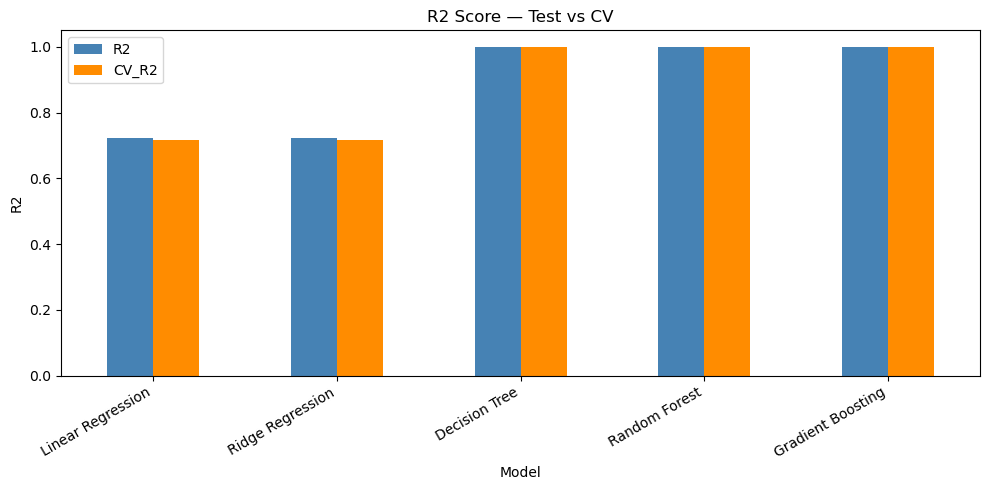

In [4]:
# =============================================================================
# Section 4 — Model Training and Comparison
# =============================================================================

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    mae  = mean_absolute_error(y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2   = r2_score(y_te, y_pred)
    # cv=3 keeps things manageable on a large dataset
    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=3, scoring='r2').mean()

    print(f'{name:<25}  MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}  CV-R2={cv_r2:.4f}')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'CV_R2': cv_r2}


results = []

# linear regression — the simplest baseline; everything else has to beat this
results.append(evaluate_model(
    'Linear Regression', LinearRegression(),
    X_train, X_test, y_train, y_test
))

# ridge — adds L2 regularisation which should help given the correlated features
results.append(evaluate_model(
    'Ridge Regression', Ridge(alpha=1.0),
    X_train, X_test, y_train, y_test
))

# decision tree — picks up non-linearities; depth capped at 6 to avoid overfitting
results.append(evaluate_model(
    'Decision Tree', DecisionTreeRegressor(max_depth=6, random_state=42),
    X_train, X_test, y_train, y_test
))

# random forest — averaging 50 trees cuts down the variance compared to one tree
results.append(evaluate_model(
    'Random Forest',
    RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1),
    X_train, X_test, y_train, y_test
))

# gradient boosting — sequential correction of errors, usually strong on tabular data
results.append(evaluate_model(
    'Gradient Boosting',
    GradientBoostingRegressor(n_estimators=100, max_depth=4, random_state=42),
    X_train, X_test, y_train, y_test
))

# summary table
results_df = pd.DataFrame(results)
print('\n=== Model Comparison (sorted by R2) ===')
print(results_df.sort_values('R2', ascending=False).to_string(index=False))

# bar chart comparing R2 vs cross-validated R2
fig, ax = plt.subplots(figsize=(10, 5))
results_df.set_index('Model')[['R2', 'CV_R2']].plot(
    kind='bar', ax=ax, color=['steelblue', 'darkorange']
)
plt.title('R2 Score — Test vs CV')
plt.ylabel('R2')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('model_comparison.png')
plt.show()

Using data from Section 3:
  Train: (195582, 25)   Test: (48896, 25)
Starting search...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Done in 614.2s
Best params: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}
Best CV R2:  0.9997838870554112

Optimised RF — test set
  R2  : 0.9998453322538021
  MAE : 0.015830107896211875
  RMSE: 0.03053808877115721


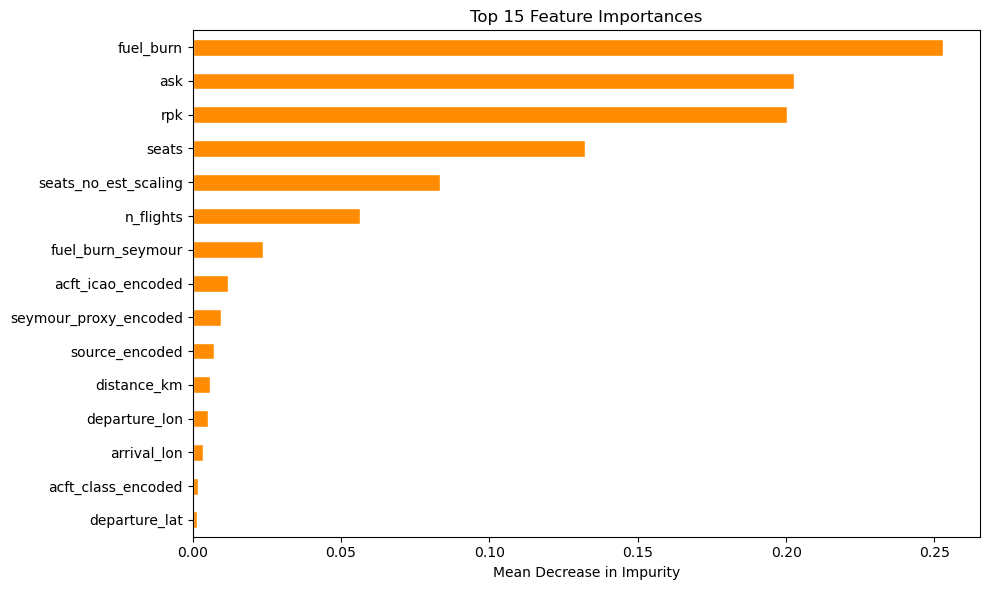

Top 10 features:
   1. fuel_burn                                     0.2527
   2. ask                                           0.2026
   3. rpk                                           0.2002
   4. seats                                         0.1321
   5. seats_no_est_scaling                          0.0833
   6. n_flights                                     0.0563
   7. fuel_burn_seymour                             0.0237
   8. acft_icao_encoded                             0.0117
   9. seymour_proxy_encoded                         0.0094
  10. source_encoded                                0.0072

Final model (top 10 features, scaled):
  R2  : 1.0000
  MAE : 0.0068
  RMSE: 0.0155


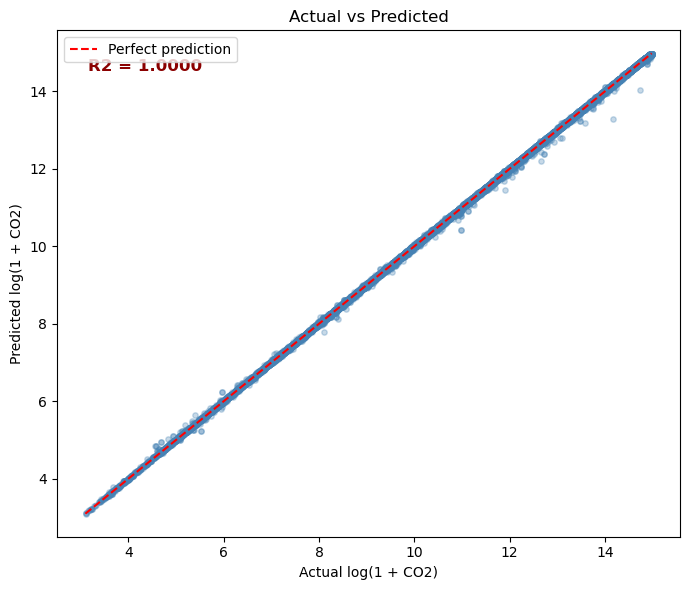

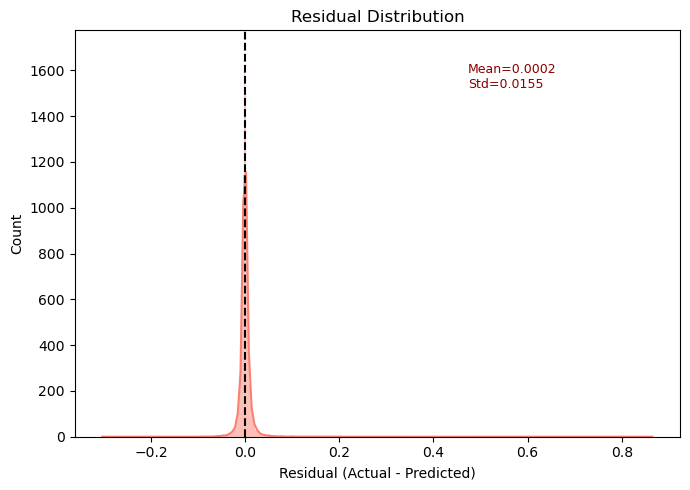


========== OPTIMISATION SUMMARY ==========
Search method : RandomizedSearchCV (n_iter=10, cv=3)
Best params   : {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}
Features used : 10
Final R2      : 1.0000
Final MAE     : 0.0068
Final RMSE    : 0.0155


In [ ]:
# =============================================================================
# Section 5 — Hyperparameter Tuning and Final Evaluation
# =============================================================================

print('Using data from Section 3:')
print('  Train:', X_train.shape, '  Test:', X_test.shape)


# --- 5.1 RandomizedSearchCV ---
param_grid = {
    'n_estimators'     : [50, 100],
    'max_depth'        : [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4],
    'max_features'     : ['sqrt', 'log2']
}

rs = RandomizedSearchCV(
    estimator           = RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions = param_grid,
    n_iter              = 10,
    cv                  = 3,
    scoring             = 'r2',
    n_jobs              = -1,
    verbose             = 1,
    random_state        = 42,
    refit               = True
)

print('Starting search...')
t0 = time.time()
rs.fit(X_train, y_train)
print(f'Done in {time.time() - t0:.1f}s')
print('Best params:', rs.best_params_)
print('Best CV R2: ', rs.best_score_)

# how does the best configuration do on the held-out test set?
best_rf  = rs.best_estimator_
ypred_rs = best_rf.predict(X_test)
print('\nOptimised RF — test set')
print('  R2  :', r2_score(y_test, ypred_rs))
print('  MAE :', mean_absolute_error(y_test, ypred_rs))
print('  RMSE:', np.sqrt(mean_squared_error(y_test, ypred_rs)))


# --- 5.2 feature importance ---
# mean decrease in impurity across all trees in the best model; 
feat_imp = pd.Series(
    best_rf.feature_importances_, index=feature_cols
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.head(15).sort_values().plot(
    kind='barh', color='darkorange', edgecolor='white', ax=ax
)
ax.set_title('Top 15 Feature Importances')
ax.set_xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 features:')
for i, (f, v) in enumerate(feat_imp.head(10).items(), 1):
    print(f'  {i:2}. {f:<45} {v:.4f}')


# --- 5.3 retrain on top 10 features ---
# trimming to the most informative features — keeps the model leaner
top10 = feat_imp.head(10).index.tolist()

# select and scale the top-10 columns using the same scaler from Section 3
# so the final model is on the same scale as all comparison models in Section 4
X_top_raw = df_clean[top10].values
X_top     = scaler.transform(df_clean[feature_cols].values)[:, [feature_cols.index(f) for f in top10]]
y_top     = df_clean['log_co2'].values

Xt2, Xe2, yt2, ye2 = train_test_split(X_top, y_top, test_size=0.2, random_state=42)

best_p = rs.best_params_.copy()
best_p['n_estimators'] = min(best_p['n_estimators'], 100)

final_rf = RandomForestRegressor(**best_p, random_state=42, n_jobs=-1)
final_rf.fit(Xt2, yt2)
yfin = final_rf.predict(Xe2)

r2f   = r2_score(ye2, yfin)
maef  = mean_absolute_error(ye2, yfin)
rmsef = np.sqrt(mean_squared_error(ye2, yfin))

print('\nFinal model (top 10 features, scaled):')
print(f'  R2  : {r2f:.4f}')
print(f'  MAE : {maef:.4f}')
print(f'  RMSE: {rmsef:.4f}')


# --- 5.4 actual vs predicted ---
# a tight cluster along the diagonal means predictions are accurate;
# fan-shaped spread would point to heteroskedasticity
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(ye2, yfin, alpha=0.3, s=15, color='steelblue')
lims = [min(ye2.min(), yfin.min()), max(ye2.max(), yfin.max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlabel('Actual log(1 + CO2)')
ax.set_ylabel('Predicted log(1 + CO2)')
ax.set_title('Actual vs Predicted')
ax.text(0.05, 0.92, f'R2 = {r2f:.4f}',
        transform=ax.transAxes, color='darkred', fontweight='bold', fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()


# --- 5.5 residuals ---
# centred near zero = no systematic bias; heavy tails would be a concern
resid = ye2 - yfin

fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(resid, kde=True, color='salmon', edgecolor='white', ax=ax)
ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax.set_title('Residual Distribution')
ax.set_xlabel('Residual (Actual - Predicted)')
ax.set_ylabel('Count')
ax.text(0.65, 0.92,
        f'Mean={resid.mean():.4f}\nStd={resid.std():.4f}',
        transform=ax.transAxes, fontsize=9, color='darkred', va='top')
plt.tight_layout()
plt.savefig('residuals.png', dpi=150, bbox_inches='tight')
plt.show()


# --- final summary printout ---
print('\n========== OPTIMISATION SUMMARY ==========')
print('Search method : RandomizedSearchCV (n_iter=10, cv=3)')
print('Best params   :', rs.best_params_)
print('Features used :', len(top10))
print(f'Final R2      : {r2f:.4f}')
print(f'Final MAE     : {maef:.4f}')
print(f'Final RMSE    : {rmsef:.4f}')
print('==========================================')
